# EE-411 — Fundamentals of Inference and Learning

## Homework 2 — Unsupervised learning

### Part 1 — Classification with the K-means algorithm

The K-means algorithm is a fundamental tool in unsupervised learning. Consider a problem with a dataset $\mathcal{D} = \left\{x_i\right\}_{i=1}^n$ where $x_i \in \mathbb{R}^d$ with no labels. We aim to find hidden structure within the data, namely clusters in the dataset. Classifiers have been studied in the exercise sessions, mainly for supervised learning. Here, the data are not labeled.

The K-means algorithm tries to classify the dataset into $K$ clusters. Each cluster is represented by a centroid, meaning the average of the points within the cluster. We denote by $C_k$ the set of points of a cluster $k$ and $\mu_k$ its centroid. Then, the algorithm minimizes the intra-cluster variance, in other words, it tries to reduce the distance between the points of the cluster and the centroid.

More technically, the algorithm works iteratively in two main steps:

- Points are assigned to clusters based on their proximity to existing centroids.
- Centroids are updated by taking the average of the points assigned to each cluster.

The loss function of the problem can be written as:
$$J(\mu_1, ..., \mu_K) = \sum_{i=1}^{n} \, \lVert x_i - \mu(i)\rVert^2 \; ,$$
where $\mu(i)$ is the centroid of the cluster assigned to $x_i$.

Let us examine the choice of this loss function. Does it match the aforementioned rules? Then, can it help us understand whether the algorithm converges?

Additionally, until Question 8, we assume that the clusters $C_k$ are disjoint, especially at initialization.

#### Question 1

First, let us familiarize ourselves with the loss function:

- Prove the second equality:

   $$J(\mu_1, ..., \mu_K) = \sum_{i=1}^{n} \, \lVert x_i - \mu(i)\rVert^2 = \sum_{k=1}^{K} \sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2$$

- What does the term $\sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2$ represent?

- Explain why this form of the loss function is more convenient.

*Answer*

First, we know that what we have on the left-hand-side is the sum of the distances from each point $x_i$ in the whole dataset to its attributed cluster's centroid $\mu_(i)$. As we know that each point is only part of one cluster, we can easily deduce that 
$$
J(\mu_1, ..., \mu_K) = \sum_{i=1}^{n} \, \lVert x_i - \mu(i)\rVert^2 = \sum_{k=1}^{K} \sum_{i: x_i \in C_k} \, \lVert x_i - \mu(i) \rVert^2
 = \sum_{k=1}^{K} \sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2
$$

Then, the term $\sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2$ represents the sum of the distances from all points of the cluster k (thus all points of the dataset $C_k$) to the centroid $\mu_k$ of this cluster (cluster k), to which they have been attributed. This metric is also called the within-cluster sum of squared distances (WCSS) of cluster k. In short, it measures the spreading of the data samples from cluster k from its centroid.

Third, this form is more convenient, because it allows for the contributions of each cluster to be separated in the loss function.

#### Question 2

Let us focus on the first step of the algorithm. Consider a single point $x_i$ and introduce the time dependence. Also, we use a prime ($'$) to denote the variables after the new assignment of the data points.

The sequence of updates is: $(\cdot)^t \to (\cdot)^t\,{}' \to (\cdot)^{t+1} \to (\cdot)^{t+1}\,{}' \to (\cdot)^{t+2}$

Thus, at each time step $t$, the new assignments satisfy (no proof required):

$$ \mu^t(i)' = \operatorname*{arg\,min}_{\mu \in \left\{\mu^t_k\right\}_k} \lVert x_i - \mu \rVert^2$$

For instance, at time $t$ before new assignments, the vector $x_i$ belongs to a cluster $k$, while after the next assignment, it now belongs to the cluster $k'$ (it can be the same or different from the cluster $k$).

Thus, for the whole dataset, the algorithm updates the assignments as follows: $\left\{\mu^t(i) \right\} \to \left\{\mu^t(i)'\right\}$.

Compare $\lVert x_i - \mu^t(i) \rVert^2$ and $\lVert x_i - \mu^t(i)' \rVert^2$ for a given point.

*Answer* 

At each time step, the reassignment works as follows. The point $x_i$ is reassigned to the cluster with the centroid closest to it (in terms of euclidean distance). 

Hence, if the point $x_i$ is reassigned to the same cluster as before, we will have 
$$
\lVert x_i - \mu^t(i)' \rVert^2 = \lVert x_i - \mu^t(i) \rVert^2 
$$

If instead the point $x_i$ is reassigned to another cluster, the distance to the new cluster centroid will be smaller
$$
\lVert x_i - \mu^t(i)' \rVert^2 < \lVert x_i - \mu^t(i) \rVert^2 
$$

Thus, for the general case we have
$$
\lVert x_i - \mu^t(i)' \rVert^2 \leq \lVert x_i - \mu^t(i) \rVert^2 
$$

#### Question 3

We recall that we use a prime ($'$) to denote the variables after the new assignment of the data points, so that: $\mu^t(i) \to \mu^t(i)'$ and $J_t \to J_t'$

Using the previous question, compare $J_t$ and ${J_t}'$.

Hint: Choose the appropriate expression from the two given for $J$.

*Answer*

We will use the first expression, as we want to compare the distances for all the individual datapoints.

We have $J_t$:
$$
J_t = \sum_{i=1}^{n} \, \lVert x_i - \mu^t(i)\rVert^2
$$

Now, after the reassignment we have $J_t'$:
$$
J_t' = \sum_{i=1}^{n} \, \lVert x_i - \mu^t(i)'\rVert^2
$$

Using the result obtained from Question 2 we get
$$
J_t' = \sum_{i=1}^{n} \, \lVert x_i - \mu^t(i)'\rVert^2 \leq \sum_{i=1}^{n} \, \lVert x_i - \mu^t(i)\rVert^2 = J_t
$$

We observe that this reassignment method yields at least the same loss and at best a lower value for the overall loss (for after the reassignment).

#### Question 4

Next, consider the second step of the algorithm, which minimizes the intra-cluster variance:

$$ \left\{\mu^{t+1}_k\right\}_k = \operatorname*{arg\,min}_{\left\{\mu_k\right\}_k \in \mathbb{R}^d} J'_t\left( \left\{\mu_k\right\}_k \right) = \operatorname*{arg\,min}_{\left\{\mu_k\right\}_k \in \mathbb{R}^d} \sum_{k=1}^{K} \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

Show that the optimization can be done cluster-wise:

$$\mu^{t+1}_k = \operatorname*{arg\,min}_{\mu_k \in \mathbb{R}^d}  \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

*Answer*

Considering the second step of the algorithm

$$ \left\{\mu^{t+1}_k\right\}_k = \operatorname*{arg\,min}_{\left\{\mu_k\right\}_k \in \mathbb{R}^d} J'_t\left( \left\{\mu_k\right\}_k \right) = \operatorname*{arg\,min}_{\left\{\mu_k\right\}_k \in \mathbb{R}^d} \sum_{k=1}^{K} \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

The last equality holds because the minimization function depends on a different variable (cluster centroid) for each cluster, thus allowing us to separate the minimization alltogether for each cluster. Therefore, this means that we can optimize each centroid separately as follows

$$\mu^{t+1}_k = \operatorname*{arg\,min}_{\mu_k \in \mathbb{R}^d}  \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

#### Question 5

Show that the new centroids at time $t+1$ are computed according to the following equality:

$$ \mu_k^{t+1} = \frac{1}{|C^t_k{}'|}\sum_{x_i \in C^t_k{}'} x_i $$

Does this correspond to what you expected from the algorithm?

*Answer*

We have to solve 
$$\mu^{t+1}_k = \operatorname*{arg\,min}_{\mu_k \in \mathbb{R}^d}  \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

We can rewrite as 
$$\mu^{t+1}_k = \operatorname*{arg\,min}_{\mu_k \in \mathbb{R}^d}  f(\mu_k) $$

With 
$$f(\mu_k) = \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 = \sum_{x_i \in C^t_k{}'} \, (x_i - \mu_k)^T (x_i - \mu_k) $$

Let's differentiate this function with respect to $\mu_k$ (our variable of interest)
$$ \nabla_{\mu_k} f(\mu_k) = -2 \sum_{x_i \in C^t_k{}'} (x_i - \mu_k)
$$

At the minimum we have stationarity, thus 
$$ \nabla_{\mu_k} f(\mu_k^*) = 0 \iff -2 \sum_{x_i \in C^t_k{}'} (x_i - \mu_k^*) = 0 \iff \sum_{x_i \in C^t_k{}'} x_i - \lvert C_k^t{}' \rvert \mu_k^* = 0 \iff \mu_k^* = \frac{1}{|C^t_k{}'|}\sum_{x_i \in C^t_k{}'} x_i
$$

As $\mu_k^{t+1}$ is the optimal $\mu_k^*$, we have proven that $$ \mu_k^{t+1} = \frac{1}{|C^t_k{}'|}\sum_{x_i \in C^t_k{}'} x_i $$

It corresponds to what we would expect, because the algorithm we are using is the K-means and indeed, the centroids are being calculated as arithmetic means.

#### Question 6

If we focus on a cluster $k$ at time $t$ after the assignment, denoted by $C^t_k {}'$, could you compare $\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^t \rVert^2$ and $\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^{t+1} \rVert^2$?

What can you say about ${J_t}'$ and $J_{t+1}$? Hint: Choose the appropriate expression from the two given for $J$.

*Answer*

From Question 4, we have
$$\mu^{t+1}_k = \operatorname*{arg\,min}_{\mu_k \in \mathbb{R}^d}  \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

Hence, the value of $\mu^{t+1}_k$ that we find using this expression minimizes the squared euclidian distance between each point $x_i$ of the cluster and the centroid of the cluster. As $\mu_k^{t+1}$ is a step more advanced than $\mu_k^t$, then it is straightforward to deduce that
$$\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^t \rVert^2 \geq \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^{t+1} \rVert^2$$

The specific case when they are equal is when the optimal centroid of the clusters is the same for both time steps.

Then, we use the second expression for the loss, because we now consider the per cluster loss. We compute the loss after the reassignment:
$$
J_t' = \sum_{k=1}^{K} \sum_{x_i \in C_k} \, \lVert x_i - \mu_k' \rVert^2
$$

And the loss at step t+1 (after the update):
$$
J_{t+1} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \, \lVert x_i - \mu_k^{t+1} \rVert^2
$$

Now let's compare them. We have that the distances can only be lower or equal at the next step, thus
$$
J_{t+1} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \, \lVert x_i - \mu_k^{t+1} \rVert^2 \leq \sum_{k=1}^{K} \sum_{x_i \in C_k} \, \lVert x_i - \mu_k' \rVert^2 = J_t'
$$

#### Question 7

Combining Questions 3 and 6, compare $J_t$ and $J_{t+1}$.

*Answer*

From Question 3, we have that $J_t' \leq J_t$.

From Question 6, we have that $J_{t+1} \leq J_t'$.

Hence overall we have $ J_{t+1} \leq J_t' \leq J_t \iff J_{t+1} \leq J_t$

Thus the loss will be at least the same and at most lower for the next step.

#### Question 8

After recalling a trivial lower bound for the sequence $(J_t)_{t \geq 0}$, what can you say about the convergence?

A trivial lower bound for $(J_t)_{t \geq 0}$ is 0, because the squared euclidian distance can never become negative. 

This means that the loss is bounded below. Recall that the algorithm monotonically decreases from Question 7 as well. Thus we have that $$\lim_{t \rightarrow \infty} J_t = J^* \geq 0$$

This ensures that the algorithm will find a minimum but it doesn't ensure that the minimum found will be the global minimum, it can be local.

#### Question 9

How sensitive is K-means to centroid initialization?

**Draw your own two-dimensional dataset** with two visually well-separated clusters, such that the algorithm with $K=2$ can converge to an undesirable clustering for some initializations.

- Draw the data points yourself.
- Mark one pair of initial centroids that leads to the expected clustering, and show the resulting clusters.
- Mark a second pair of initial centroids that leads to an undesirable clustering, and show the resulting clusters.
- Briefly explain why the initialization matters.

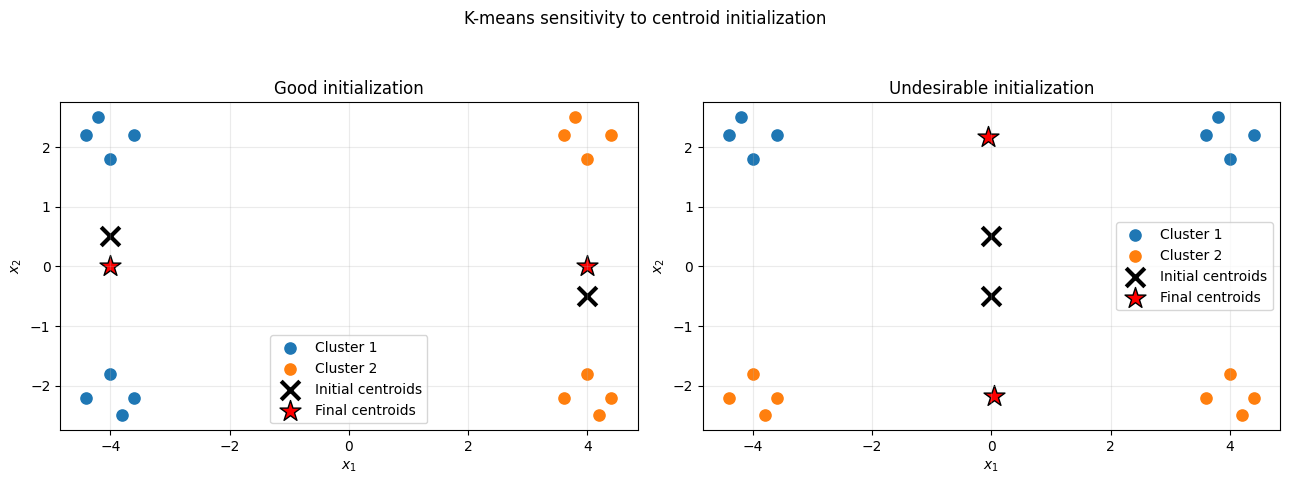

In [3]:
# TODO do better

import numpy as np
import matplotlib.pyplot as plt

# 1. Create a 2D dataset with two well-separated clusters
np.random.seed(42)

left = np.array([
    [-4.4, 2.2], [-4.0, 1.8], [-3.6, 2.2],
    [-4.4, -2.2], [-4.0, -1.8], [-3.6, -2.2],
    [-4.2, 2.5], [-3.8, -2.5]
])

right = np.array([
    [3.6, 2.2], [4.0, 1.8], [4.4, 2.2],
    [3.6, -2.2], [4.0, -1.8], [4.4, -2.2],
    [3.8, 2.5], [4.2, -2.5]
])

X = np.vstack([left, right])

# 2. Good initialization: one centroid in each natural cluster
good_centroids = np.array([
    [-4.0, 0.5],
    [4.0, -0.5]
])

# 3. Bad initialization: both centroids in the gap,
# one above and one below the horizontal axis
bad_centroids = np.array([
    [0.0, 0.5],
    [0.0, -0.5]
])

# 4. K-means implementation
def kmeans(X, centroids, max_iter=100):
    centroids = centroids.astype(float).copy()

    for _ in range(max_iter):
        # Assignment step
        distances = np.linalg.norm(
            X[:, None, :] - centroids[None, :, :],
            axis=2
        )
        labels = np.argmin(distances, axis=1)

        # Update step
        new_centroids = np.array([
            X[labels == k].mean(axis=0)
            for k in range(len(centroids))
        ])

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return labels, centroids

# 5. Run K-means with both initializations
good_labels, good_final = kmeans(X, good_centroids)
bad_labels, bad_final = kmeans(X, bad_centroids)

# 6. Plot the results
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

results = [
    (good_labels, good_centroids, good_final,
     "Good initialization"),
    (bad_labels, bad_centroids, bad_final,
     "Undesirable initialization")
]

for ax, (labels, initial, final, title) in zip(axes, results):

    ax.scatter(
        X[labels == 0, 0], X[labels == 0, 1],
        label="Cluster 1", s=65
    )

    ax.scatter(
        X[labels == 1, 0], X[labels == 1, 1],
        label="Cluster 2", s=65
    )

    # Initial centroids: crosses
    ax.scatter(
        initial[:, 0], initial[:, 1],
        marker="x", s=180, linewidths=3,
        color="black", label="Initial centroids"
    )

    # Final centroids: stars
    ax.scatter(
        final[:, 0], final[:, 1],
        marker="*", s=250, color="red",
        edgecolors="black", label="Final centroids"
    )

    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.legend()
    ax.grid(alpha=0.25)
    ax.set_aspect("equal")

plt.suptitle("K-means sensitivity to centroid initialization")
plt.tight_layout()
plt.show()


*Answer*

The initialization matters as shown in the graphs above. This is because different initial centroids can lead to different reassignments of the centroids and thus different final clusters. 

#### Question 10

What can you say about those configurations of centroids? What does it imply concerning the minima? Conclude your arguments by discussing the convexity of the problem.

*Answer*

We can see directly that when using a certain configuration of centroids as initialization in the case of the data shown in Question 9, initializing the centroids in the middle of the data that makes up each cluster, the algorithm converges to the global optimum. When instead we initialize the centroids in the middle of all the data, then the optimum is not the global one.

These configurations of centroids, as mentioned in Question 9, lead to different reassignments during the algorithm computation. This leads to the algorithm converging to a local minimum instead of the global one, as this has already been mentionned in Question 8.

This is the issue with non-convex problems like this one. A convex problem would lead to a global (unique) optimal value of the centroids, but with a non-convex problem, we can end up with a non-global optimum (there can be multiple local minima).

#### Question 11

We can also quickly generalize our algorithm.

In some situations, you are aiming at favoring some directions in your data and penalizing the others, so that you can weigh the Euclidean distance according to:

$$d^{(w)}(x_{i}, \mu(i)) = \frac{\sum_{j=1}^d w_j(x_{ij} - \mu(i)_j)^2}{\sum_{j=1}^d w_j} $$

Assume $w_j > 0$ for every coordinate $j$.

Show that with a change of variables, the problem remains the same.

In [4]:
# TODO check

*Answer*

Let's introduce a change of variables:
$$
\tilde{x}_{ij} = \sqrt{w_j} x_{ij}, \quad \tilde{\mu}_{kj} = \sqrt{w_j} \mu_{kj} \iff \tilde{\mu}(i)_j = \sqrt{w_j} \mu(i)_j
$$

Rewrite the weighted euclidean distance:
$$d^{(w)}(x_{i}, \mu(i)) = \frac{\sum_{j=1}^d w_j(x_{ij} - \mu(i)_j)^2}{\sum_{j=1}^d w_j} 
= \frac{\sum_{j=1}^d (\sqrt{w_j} (x_{ij} - \mu(i)_j))^2}{\sum_{j=1}^d w_j}$$

Deploying the change of variables into it:
$$
d^{(w)}(\tilde{x}_{i}, \tilde{\mu}(i)) = \frac{\sum_{j=1}^d (\tilde{x}_{ij} - \tilde{\mu}(i)_j)^2}{\sum_{j=1}^d w_j} 
= \frac{\lVert \tilde{x}_{i} - \tilde{\mu}(i) \rVert^2}{\sum_{j=1}^d w_j} 
$$

As the weights are strictly positive and assumed constant, we have that the problem will remain the same with just a difference of a constant, namely $\sum_{j=1}^d w_j$.

### Part 2 — Restricted Boltzmann machines

#### Introduction

Boltzmann machines are inspired by models from thermodynamics and statistical physics. More precisely, they are energy-based models that use the well-known Boltzmann distribution, written in physics notation as:

$$ P\left( E \right)  = \frac{1}{Z} \exp \left( -\frac{E}{k_b T} \right)$$

In the statistical inference framework, this becomes:
$$
P(\mathbf{v} \mid J, \mathbf{b}) \propto e^{\mathbf{v}^\top J\mathbf{v} + \mathbf{b}^\top\mathbf{v}} = e^{-E(\mathbf{v})}
$$
where:

- $\mathbf{v}\in\mathbb{R}^n:$ The binary vector with components $v_i = 0 \; \text{or} \; 1$

- $J \in \mathbb{R}^{n \times n}:$ The coupling matrix

- $\mathbf{b} \in  \mathbb{R}^n$: Field

- $E(\mathbf{v}) \in  \mathbb{R}$: Energy

However, one problem arose with the original Boltzmann machine (BM) — as with its parent models in statistical physics (such as the SK model) — all the units interact through complicated dependencies. For example, if we consider 3 components of $\mathbf{v}$: $v_1$, $v_2$, and $v_3$, there are trivial interactions such as the one modeled by $P(v_1, v_2)$ corresponding to the correlation between the first two components of $\mathbf{v}$, but there are also nontrivial interactions. Indeed, a term such as $P(v_1, v_2 \mid v_3)$ suggests that the correlation between $x_1$ and $v_2$ depends on $v_3$ and this is clearly nonlinear.

A really ingenious way to overcome this situation is to replace all the tricky interactions between the units $\mathbf{v}\in\mathbb{R}^n$ by connections through hidden units $\mathbf{h}\in\mathbb{R}^m$, artificially created. Indeed, correlations between two units $v_1$ and $v_2$ (especially the dependence of their correlations on other units $v_3$, $v_4$,...) can be artificially replaced by introducing a third unit $h_1$ and considering only linear correlations between $v_1 \leftrightarrow h_1$, $h_1 \leftrightarrow v_2$ and $v_1 \leftrightarrow v_2$. The units $v_i$ are now called the visible units. This model is the best-known version of BMs.

<div style="text-align: center;">
    <img src="boltzmannmachine.png" alt="Diagram here" />
</div>

However, this model is still fully connected and makes the computation really costly. Then, one can even simplify the model by considering zero interactions within each layer. This simplified model is called a restricted Boltzmann machine (RBM) (Nobel Prize in Physics 2024 🥳).

Thus, the RBM architecture consists of two layers of binary stochastic units: a **visible layer** $\mathbf{v}$ and a **hidden layer** $\mathbf{h}$. The layers are fully connected, but there are no connections within a layer, making the model a **bipartite graph**.

<div style="text-align: center;">
    <img src="rbm.png" alt="Diagram here" />
</div>

Restricted Boltzmann Machines (RBMs) are a class of energy-based probabilistic graphical models that are commonly used in machine learning for tasks such as dimensionality reduction, feature learning, and generative modeling.

#### Energy function and probabilities

The joint configuration of the visible units $\mathbf{v} \in \{0, 1\}^d$ and the hidden units $\mathbf{h} \in \{0, 1\}^m$ is associated with an **energy function**, defined as:

$$ E(\mathbf{v}, \mathbf{h}) = -\mathbf{v}^\top \mathbf{W} \mathbf{h} - \mathbf{b}^\top \mathbf{v} - \mathbf{c}^\top \mathbf{h}$$
where:

- $\mathbf{W} \in \mathbb{R}^{d \times m}$ is the weight matrix connecting the visible and hidden units,
- $\mathbf{b} \in \mathbb{R}^d$ is the field of the visible units, also called their biases,
- $\mathbf{c} \in \mathbb{R}^m$ is the field of the hidden units, also called their biases.

The energy function determines the joint probability distribution over $\mathbf{v}$ and $\mathbf{h}$:
$$ P(\mathbf{v}, \mathbf{h}) = \frac{1}{Z} \exp(-E(\mathbf{v}, \mathbf{h})) $$
where $Z$ is the **partition function**, ensuring normalization:

$$ Z = \sum_{\mathbf{v}, \mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h})) $$

The marginal probability of the visible units $\mathbf{v}$ is obtained by summing over all possible configurations of the hidden units:

$$ P(\mathbf{v}) = \frac{1}{Z} \sum_{\mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h})). $$

#### Question 12

Write a valid expression of the energy $E(\mathbf{v}, \mathbf{h})$ in the case of a BM (non-restricted) with a hidden layer.

We begin from the Boltzmann distribution:
$$
P(\mathbf{v} \mid J, \mathbf{b}) \propto e^{\mathbf{v}^\top J\mathbf{v} + \mathbf{b}^\top\mathbf{v}} = e^{-E(\mathbf{v})}
$$
where:

- $\mathbf{v}\in\mathbb{R}^n:$ The binary vector with components $v_i = 0 \; \text{or} \; 1$

- $J \in \mathbb{R}^{n \times n}:$ The coupling matrix

- $\mathbf{b} \in  \mathbb{R}^n$: Field

- $E(\mathbf{v}) \in  \mathbb{R}$: Energy

Thus we get the expression for the energy 
$$
E(\mathbf{v}) = -\mathbf{v}^\top J\mathbf{v} - \mathbf{b}^\top\mathbf{v}
$$

Now considering 1 visible and 1 hidden layer
$$
\mathbf x=
\begin{pmatrix}
\mathbf v\\
\mathbf h
\end{pmatrix}
$$

With their biases
$$
\mathbf b'=
\begin{pmatrix}
\mathbf b\\
\mathbf c
\end{pmatrix}
$$

The matrix describing the interactions is now
$$
J'=
\begin{pmatrix}
J_v & W \\
W^\top & J_h
\end{pmatrix}
$$

With:

- $J_v$ describing the visible - visible units interactions
- $J_h$ describing the hidden - hidden units interactions
- $W$ describing the visible - hidden units interactions (symmetric)

Let's rewrite the energy expression:
$$
E(\mathbf{x}) = -\mathbf{x}^\top J'\mathbf{x} - \mathbf{b'}^\top\mathbf{x}
$$

And replace the expressions and expand it:
$$
E(\mathbf{v}, \mathbf{h}) = -\begin{pmatrix}\mathbf v^\top&\mathbf h^\top\end{pmatrix}
\begin{pmatrix}J_v&W\\W^\top&J_h\end{pmatrix}
\begin{pmatrix}\mathbf v\\\mathbf h\end{pmatrix}
-\mathbf b^\top\mathbf v-\mathbf c^\top\mathbf h
=-\mathbf v^\top J_v\mathbf v -\mathbf v^\top W\mathbf h -\mathbf h^\top W^\top\mathbf v
-\mathbf h^\top J_h\mathbf h
-\mathbf b^\top\mathbf v-\mathbf c^\top\mathbf h
$$

In [7]:
# TODO check: The RBM formulation of the energy is different in that the $J_v$ and $J_h$ are zero, 
# as the interactions within the layers are removed.???

#### Conditional independence

#### Question 13

One of the key properties of RBMs is the **conditional independence** between units within a layer:

Compute the conditional probability and show that:

$$ P(h_j = 1 \mid \mathbf{v}) = \sigma\left(c_j + \sum_{i} v_i W_{ij}\right) $$
and
$$ P(v_i = 1 \mid \mathbf{h}) = \sigma\left(b_i + \sum_{j} h_j W_{ij}\right) $$

where $\sigma(x) = \frac{1}{1 + e^{-x}}$ is the sigmoid activation function.

This bipartite structure enables efficient Gibbs sampling for approximating the intractable joint distribution $P(\mathbf{v}, \mathbf{h})$.

Knowing that for a RBM the energy is:
$$
\begin{aligned}
E(\mathbf v,\mathbf h)
&= -\mathbf v^\top W\mathbf h
-\mathbf b^\top\mathbf v
-\mathbf c^\top\mathbf h\\
&= -\sum_i{\sum_j{v_iW_{ij}h_j}} - \sum_i{b_iv_i} - \sum_j{c_jh_j}
\end{aligned}
$$

The energy function determines the joint probability distribution over $\mathbf{v}$ and $\mathbf{h}$:
$$ P(\mathbf{v}, \mathbf{h}) = \frac{1}{Z} \exp(-E(\mathbf{v}, \mathbf{h})) $$
where $Z$ is the **partition function**, ensuring normalization:

$$ Z = \sum_{\mathbf{v}, \mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h})) $$

The marginal probability of the visible units $\mathbf{v}$ is obtained by summing over all possible configurations of the hidden units:

$$ P(\mathbf{v}) = \frac{1}{Z} \sum_{\mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h})). $$

The conditional probability for $h_j$ is

$$
\begin{aligned}
P(h_j\mid\mathbf v)
&= \frac{\frac{1}{Z} P(\mathbf v, h_j)}{\frac{1}{Z} P(\mathbf v)}\\
&= \frac{\exp({-E(\mathbf v,h_j)})}
{\sum_{\mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h}))}
\end{aligned}
$$

Now let's compute $P(h_j = 1 \mid \mathbf{v})$:
$$
\begin{aligned}
P(h_j = 1 \mid \mathbf{v})
&= \frac{\exp(-E(\mathbf v,h_j=1))}
{\exp(-E(\mathbf v,h_j=1))+\exp(-E(\mathbf v,h_j=0))} \\

&= \frac{\exp(1 \cdot (\sum_i{v_iW_{ij}} + c_j) + \sum_i{b_iv_i})}{\exp(1 \cdot (\sum_i{v_iW_{ij}} + c_j) + \sum_i{b_iv_i}) + \exp(0 \cdot (\sum_i{v_iW_{ij}} + c_j) + \sum_i{b_iv_i})}\\

&= \frac{\exp(\sum_i{v_iW_{ij}} + c_j) \cdot \exp(\sum_i{b_iv_i})}{\exp(\sum_i{v_iW_{ij}} + c_j) \cdot \exp(\sum_i{b_iv_i}) + \exp(\sum_i{b_iv_i})}\\

&= \frac{\exp(\sum_i{v_iW_{ij}} + c_j)}{\exp(\sum_i{v_iW_{ij}} + c_j) + 1}\\

&= \frac{1}{1 + \exp(-(\sum_i{v_iW_{ij}} + c_j))}\\

&= \sigma\left(c_j + \sum_i v_i W_{ij}\right)
\end{aligned}
$$

Similarly, the marginal probability of the hidden units $\mathbf{h}$ is obtained by summing over all possible configurations of the visible units:

$$ P(\mathbf{h}) = \frac{1}{Z} \sum_{\mathbf{v}} \exp(-E(\mathbf{v}, \mathbf{h})). $$

The conditional probability for $v_i$ is

$$
\begin{aligned}
P(v_i\mid\mathbf h)
&= \frac{\frac{1}{Z} P(v_i, \mathbf h)}{\frac{1}{Z} P(\mathbf h)}\\
&= \frac{\exp({-E(v_i , \mathbf h)})}
{\sum_{\mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h}))}
\end{aligned}
$$

Now let's compute $P(v_i = 1 \mid \mathbf{h})$:
$$
\begin{aligned}
P(v_i = 1 \mid \mathbf{h})
&= \frac{\exp(-E(v_i=1, \mathbf h))}
{\exp(-E(v_i=1, \mathbf h))+\exp(-E(v_i=0, \mathbf h))}\\

&= \frac{\exp(1 \cdot (\sum_j{W_{ij}h_j} + b_i) + \sum_j{c_jh_j})}{\exp(1 \cdot (\sum_j{W_{ij}h_j} + b_i) + \sum_j{c_jh_j}) + \exp(0 \cdot (\sum_j{W_{ij}h_j} + b_i) + \sum_j{c_jh_j})}\\

&= \frac{\exp(\sum_j{W_{ij}h_j} + b_i) \cdot \exp(\sum_j{c_jh_j})}{\exp(\sum_j{W_{ij}h_j} + b_i) \cdot \exp(\sum_j{c_jh_j}) + \exp(\sum_j{c_jh_j})}\\

&= \frac{\exp(\sum_j{W_{ij}h_j} + b_i)}{\exp(\sum_j{W_{ij}h_j} + b_i) + 1}\\

&= \frac{1}{1 + \exp(-(\sum_j{W_{ij}h_j} + b_i))}\\

&= \sigma\left(b_i + \sum_j{W_{ij}h_j}\right)
\end{aligned}
$$

#### Learning in RBMs

#### Question 14

Training an RBM involves maximizing the likelihood of the data distribution. To do so, we aim to use gradient descent/ascent on the weights (and biases).

Compute the log-likelihood $\mathcal{L}(\mathbf{v})$. Recall that this is an unsupervised learning model.

The log-likelihood is
$$
\mathcal L(\mathbf v)=\log P(\mathbf v)
$$

Now we need to compute $P(\mathbf v)$. For that, we use the fact that the model is unsupervised and thus we only observe the visible units $\mathbf v$. Thus as given in the explanation of RBMs before we have:
$$
P(\mathbf v) = \sum_{\mathbf h}P(\mathbf v,\mathbf h) = \frac{1}{Z}\sum_{\mathbf h} \exp(-E(\mathbf v,\mathbf h))
$$

Thus 
$$
\begin{aligned}
\mathcal L(\mathbf v)=\log P(\mathbf v)
&= \log (\frac{1}{Z} \sum_{\mathbf h} \exp(\mathbf v^\top W\mathbf h
+\mathbf b^\top\mathbf v
+\mathbf c^\top\mathbf h))\\

&= \log (\sum_{\mathbf h} \exp(\mathbf v^\top W\mathbf h
+\mathbf b^\top\mathbf v
+\mathbf c^\top\mathbf h)) - \log(Z)\\

&= \mathbf b^\top\mathbf v
+ \log (\sum_{\mathbf h} \exp(\mathbf v^\top W\mathbf h
+\mathbf c^\top\mathbf h)) - \log(Z)
\end{aligned}
$$


#### Question 15

Compute the gradient of the log-likelihood with respect to the weights $\mathbf{W}$ and the biases $\mathbf{b}$, $\mathbf{c}$:

In [8]:
# TODO!!!

Now, it should be possible to implement the RBM!

#### Question 16 (open question)

While it seems possible to run the RBM algorithm, note that the second term in the gradient with respect to $\mathbf{W}$ is computationally expensive due to the intractability of $Z$. The contrastive divergence approximation (CD-$k$) is often used. Research this approximation. Is it sufficient, and why? Explain in your own words and cite the papers you consulted.

In [9]:
# TODO

#### Applications of RBMs

RBMs are widely used in tasks such as:

- **Dimensionality reduction**: Similar to PCA but capable of capturing non-linear structures,
- **Feature learning**: For pre-training deep neural networks,
- **Collaborative filtering**: Used in recommendation systems.